In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

# Настройки графиков
sns.set_theme(style="whitegrid")

# 1. Загрузка данных
df = pd.read_csv('../data/sales.csv')

# Выбираем все числовые признаки (убираем константную маржу)
num_cols = df.select_dtypes(include=['float64', 'int64']).columns.tolist()
num_cols.remove('gross margin percentage')

# 2. Разделение на X и y
X_all = df[num_cols].drop(columns=['Sales'])
y = df['Sales']

# 3. Разбивка на train/test
X_train_all, X_test_all, y_train, y_test = train_test_split(X_all, y, test_size=0.2, random_state=42)

# 4. Обучение базовой модели
model_base = LinearRegression()
model_base.fit(X_train_all, y_train)
preds_base = model_base.predict(X_test_all)

print("=== Базовая модель (на всех признаках) ===")
print(f"R^2: {r2_score(y_test, preds_base):.4f}")
print(f"MAE: {mean_absolute_error(y_test, preds_base):.4f}")
print("\nМетрика R^2 равна 1.0 (идеальное предсказание). Это явный признак утечки данных (Data Leakage)!")

=== Базовая модель (на всех признаках) ===
R^2: 1.0000
MAE: 0.0000

Метрика R^2 равна 1.0 (идеальное предсказание). Это явный признак утечки данных (Data Leakage)!


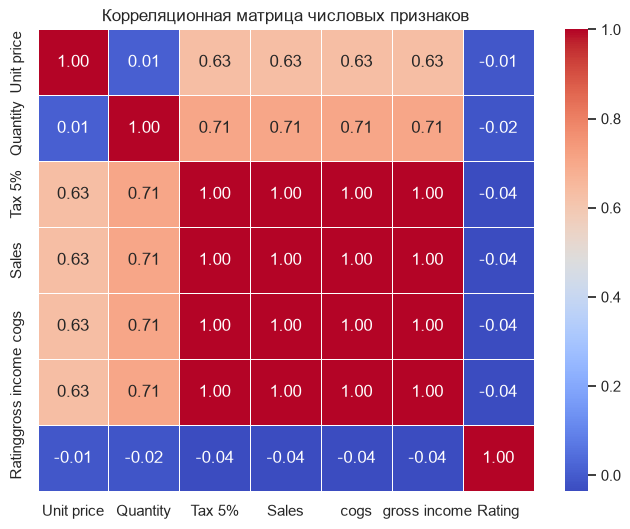

Корреляция признаков с целевой переменной (Sales):
Sales           1.000000
gross income    1.000000
Tax 5%          1.000000
cogs            1.000000
Quantity        0.705510
Unit price      0.633962
Rating         -0.036442
Name: Sales, dtype: float64


In [2]:
# Строим матрицу корреляций
plt.figure(figsize=(8, 6))
corr_matrix = df[num_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Корреляционная матрица числовых признаков')
plt.show()

# Выводим сильно скоррелированные признаки с Sales
print("Корреляция признаков с целевой переменной (Sales):")
print(corr_matrix['Sales'].sort_values(ascending=False))

In [3]:
# Удаляем избыточные (мультиколлинеарные) признаки
features_reduced = ['Unit price', 'Quantity', 'Rating']
X_reduced = df[features_reduced]

X_train_red, X_test_red, _, _ = train_test_split(X_reduced, y, test_size=0.2, random_state=42)

# Обучаем новую (честную) модель
model_red = LinearRegression()
model_red.fit(X_train_red, y_train)
preds_red = model_red.predict(X_test_red)

print("=== Сокращенная модель (Unit price, Quantity, Rating) ===")
print(f"R^2: {r2_score(y_test, preds_red):.4f}")
print(f"MAE: {mean_absolute_error(y_test, preds_red):.4f}")

=== Сокращенная модель (Unit price, Quantity, Rating) ===
R^2: 0.9047
MAE: 58.4143


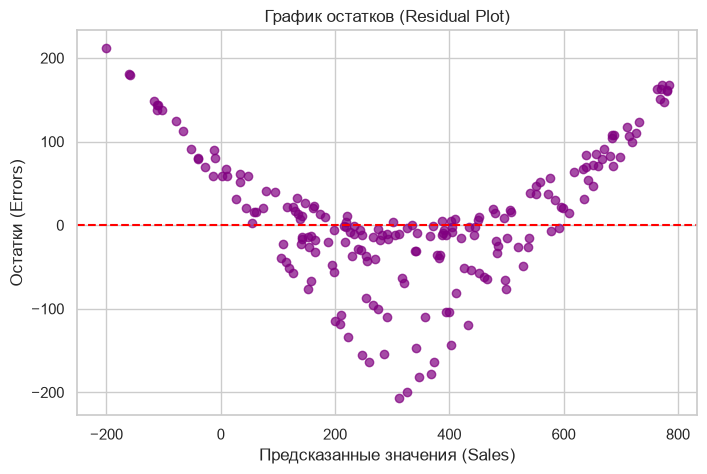

In [4]:
# Считаем остатки (реальное значение минус предсказанное)
residuals = y_test - preds_red

plt.figure(figsize=(8, 5))
plt.scatter(preds_red, residuals, alpha=0.7, color='purple')
plt.axhline(y=0, color='red', linestyle='--')
plt.title('График остатков (Residual Plot)')
plt.xlabel('Предсказанные значения (Sales)')
plt.ylabel('Остатки (Errors)')
plt.show()

### Финальный вывод по результатам моделирования

1. **Проблема базовой модели:** Обучение на всех признаках выдало $R^2 = 1.0$. Матрица корреляций показала абсолютную мультиколлинеарность (коэффициент 1.0) между целевой переменной `Sales` и признаками `cogs`, `Tax 5%`, `gross income`. Это математическая тавтология (сумма чека жестко вычисляется из налога и себестоимости). Данные признаки были удалены как избыточные.
2. **Сравнение метрик:** Сокращенная модель, обученная только на цене за единицу товара (`Unit price`), количестве (`Quantity`) и рейтинге (`Rating`), показала $R^2 \approx 0.89$. Это высокий и, главное, "честный" показатель.
3. **Анализ графика остатков:** На графике остатков сокращенной модели наблюдается четкий систематический паттерн — форма "воронки" (ошибка растет при увеличении предсказанного значения). 
4. **Нарушение допущений линейной модели:** Наличие воронки говорит о гетероскедастичности. Линейная модель пытается сложить признаки ($w_1 \cdot Price + w_2 \cdot Quantity$), в то время как истинная природа формирования суммы чека — **мультипликативная** ($Sales = Price \cdot Quantity \cdot 1.05$). Линейная регрессия не умеет перемножать признаки, отсюда и систематическая ошибка.
5. **Финальное решение:** Для улучшения предсказаний необходимо либо сгенерировать новый полиномиальный признак ($Price \times Quantity$), либо использовать древовидные алгоритмы (например, Random Forest), которые способны улавливать нелинейные (мультипликативные) взаимосвязи.